\
# SOS Enchente — Zonas de Risco de São Paulo para priorização de resgates

**Objetivo:** agrupar os distritos de São Paulo em *Zonas de Risco* a partir de duas variáveis reais: vulnerabilidade social (famílias em extrema pobreza — ObservaSampa 2025) e exposição a alagamentos (chamados SP156 de Alagamento/Inundação em 2025). O resultado apoia a Defesa Civil na alocação **preventiva** de barcos, ambulâncias e equipes do SUS.

**Fontes — dados públicos da Prefeitura de São Paulo (nenhum dado simulado):**
- `ObservaSampaDadosAbertosIndicadoresCSV.csv` — indicador `01.01.01 Quantidade de famílias em situação de extrema pobreza (até 1/4 salário mínimo)`, ano 2025.
- `SP156-Database.csv` — chamados dos serviços **Alagamento** e **Inundação**, ano 2025.


In [1]:
\
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
K_RANGE = range(2, 11)


def normalizar_nome(valor):
    
    texto = unicodedata.normalize('NFKD', str(valor)).encode('ascii', 'ignore').decode('utf-8')
    return re.sub(r'[^A-Z0-9]+', ' ', texto.upper()).strip()


def mapa_colunas(dataframe):

    return {normalizar_nome(coluna).lower(): coluna for coluna in dataframe.columns}


def localizar_arquivo(nomes):
    diretorios = [Path.cwd(), Path.cwd().parent, Path('C:/Repositories/SOS-ENCHENTE')]
    for diretorio in diretorios:
        for nome in nomes:
            candidato = diretorio / nome
            if candidato.is_file():
                return candidato
    raise FileNotFoundError(f'Não encontrado nenhum destes arquivos: {nomes}')


def detectar_delimitador(caminho, encoding):
    with open(caminho, 'r', encoding=encoding, errors='replace') as arquivo:
        cabecalho = arquivo.readline()
    return '|' if cabecalho.count('|') >= cabecalho.count(';') else ';'


CAMINHO_POBREZA = localizar_arquivo([
    'ObservaSampaDadosAbertosIndicadoresCSV.csv', 'pobreza_observasampa.csv'
])
CAMINHO_SP156 = localizar_arquivo(['SP156-Database.csv', 'alagamentos_sp156.csv'])
SEP_POBREZA = detectar_delimitador(CAMINHO_POBREZA, 'utf-8')
SEP_SP156 = detectar_delimitador(CAMINHO_SP156, 'cp1252')

print('Pobreza :', CAMINHO_POBREZA, '| delimitador =', repr(SEP_POBREZA))
print('SP156   :', CAMINHO_SP156, '| delimitador =', repr(SEP_SP156))

Pobreza : c:\Repositories\SOS-ENCHENTE\ObservaSampaDadosAbertosIndicadoresCSV.csv | delimitador = '|'
SP156   : c:\Repositories\SOS-ENCHENTE\SP156-Database.csv | delimitador = '|'


\
## 1. Limpeza e preparação dos dados

### 1.1 ObservaSampa — famílias em extrema pobreza

O arquivo contém centenas de indicadores e vários anos. Mantemos apenas o indicador de extrema pobreza, o ano 2025 e as linhas cuja `Região` é um **distrito** (excluímos subprefeituras e o total do município, que não são unidades de clusterização). Em seguida removemos o sufixo `" (Distrito)"`.

In [2]:
\
pobreza_bruta = pd.read_csv(CAMINHO_POBREZA, sep=SEP_POBREZA, encoding='utf-8', dtype=str)
col_pob = mapa_colunas(pobreza_bruta)
print(f'ObservaSampa: {pobreza_bruta.shape[0]:,} linhas brutas | {pobreza_bruta.shape[1]} colunas')
print('Colunas:', list(pobreza_bruta.columns))

ausentes = [chave for chave in ('nome', 'regiao', 'periodo', 'resultado') if chave not in col_pob]
if ausentes:
    raise KeyError(f'Colunas obrigatórias não encontradas no ObservaSampa: {ausentes}')

filtro_pobreza = (
    pobreza_bruta[col_pob['nome']].str.contains('extrema pobreza', case=False, na=False)
    & pobreza_bruta[col_pob['periodo']].astype(str).str.strip().eq('2025')
    & pobreza_bruta[col_pob['regiao']].str.contains('(Distrito)', regex=False, na=False)
)

pobreza = pobreza_bruta.loc[filtro_pobreza, [col_pob['regiao'], col_pob['resultado']]].copy()
pobreza.columns = ['Regiao_original', 'Resultado']
pobreza['Distrito'] = pobreza['Regiao_original'].str.replace(' (Distrito)', '', regex=False).str.strip()
pobreza['Extrema_Pobreza'] = pd.to_numeric(
    pobreza['Resultado'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
    errors='coerce',
)
pobreza = (
    pobreza.dropna(subset=['Extrema_Pobreza'])
    .drop_duplicates(subset='Distrito', keep='last')
    [['Distrito', 'Extrema_Pobreza']]
    .reset_index(drop=True)
)

print(f'Após filtros: {len(pobreza)} distritos (apenas 2025 + extrema pobreza)')
print(f'Mínimo={pobreza.Extrema_Pobreza.min():,.0f} | média={pobreza.Extrema_Pobreza.mean():,.0f} | máximo={pobreza.Extrema_Pobreza.max():,.0f}')
pobreza.head(8)

ObservaSampa: 206,198 linhas brutas | 4 colunas
Colunas: ['Nome', 'Região', 'Período', 'Resultado']
Após filtros: 96 distritos (apenas 2025 + extrema pobreza)
Mínimo=84 | média=5,025 | máximo=18,360


,Distrito,Extrema_Pobreza
0,Água Rasa,1560
1,Alto de Pinheiros,99
2,Anhanguera,3755
3,Aricanduva,3069
4,Artur Alvim,4877
5,Barra Funda,310
6,Bela Vista,2145
7,Belém,3874


\
### 1.2 SP156 — chamados de alagamento

O SP156 disponibilizado tem ~2,6 milhões de registros de **todos os temas**. Agrupar tudo geraria ruído (capinação, tapa-buraco etc.). Por isso filtramos os serviços `Alagamento` e `Inundação` da área de Defesa Civil. A leitura é feita em blocos de 200 mil linhas para não carregar os 485 MB inteiros na memória, e os nomes dos distritos são normalizados para permitir o merge.

In [3]:
\
cabecalho_sp = pd.read_csv(CAMINHO_SP156, sep=SEP_SP156, encoding='cp1252', nrows=0)
col_sp = mapa_colunas(cabecalho_sp)
print('Colunas SP156:', list(cabecalho_sp.columns))

col_distrito_sp = col_sp.get('distrito')
col_data_sp = col_sp.get('data de abertura') or col_sp.get('data')
col_servico_sp = col_sp.get('servico')

if col_distrito_sp is None:
    raise KeyError('Coluna de distrito não encontrada no CSV do SP156.')

if col_servico_sp is not None:
    
    usecols = [c for c in (col_distrito_sp, col_servico_sp, col_data_sp) if c]
    pedacos, total_chamados = [], 0
    for pedaco in pd.read_csv(
        CAMINHO_SP156, sep=SEP_SP156, encoding='cp1252', dtype=str,
        usecols=usecols, chunksize=200_000, on_bad_lines='skip'
    ):
        servico = pedaco[col_servico_sp].fillna('').map(normalizar_nome)
        selecao = servico.isin({'ALAGAMENTO', 'INUNDACAO'})
        if col_data_sp:
            ano = pedaco[col_data_sp].astype(str).str.extract(r'(\d{4})\s*$')[0]
            selecao &= ano.eq('2025').fillna(False)
        parte = pedaco.loc[selecao, [col_distrito_sp]].copy()
        parte['Distrito'] = parte[col_distrito_sp].fillna('').map(normalizar_nome)
        parte = parte[parte['Distrito'] != ''][['Distrito']]
        total_chamados += len(parte)
        pedacos.append(parte)
    base_alagamentos = pd.concat(pedacos, ignore_index=True)
    alagamentos = base_alagamentos.groupby('Distrito').size().reset_index(name='Total_Alagamentos')
    print(f'Chamados de Alagamento/Inundação em 2025: {total_chamados:,}')
else:
    
    candidatos = ['total alagamentos', 'alagamentos', 'ocorrencias', 'chamados', 'quantidade', 'total']
    col_contagem = next((col_sp[ch] for ch in candidatos if ch in col_sp), None)
    base_alagamentos = pd.read_csv(CAMINHO_SP156, sep=SEP_SP156, encoding='cp1252', dtype=str)
    if col_contagem:
        base_alagamentos['Total_Alagamentos'] = pd.to_numeric(base_alagamentos[col_contagem], errors='coerce').fillna(0)
    else:
        base_alagamentos['Total_Alagamentos'] = 1
    base_alagamentos['Distrito'] = base_alagamentos[col_distrito_sp].fillna('').map(normalizar_nome)
    base_alagamentos = base_alagamentos[base_alagamentos['Distrito'] != '']
    alagamentos = base_alagamentos.groupby('Distrito', as_index=False)['Total_Alagamentos'].sum()
    print(f'Base agregada lida: {len(base_alagamentos):,} linhas por distrito')

print(f'Distritos com chamados: {len(alagamentos)}')
print(f'Soma total de alagamentos: {int(alagamentos.Total_Alagamentos.sum()):,}')
alagamentos.sort_values('Total_Alagamentos', ascending=False).head(8)

Colunas SP156: ['Data de Abertura', 'Data de Finalização', 'Meio de Comunicação', 'Tema', 'Assunto', 'Serviço', 'Status', 'Órgão', 'Logradouro', 'Número', 'CEP', 'Latitude', 'Longitude', 'Prefeitura Operacional', 'Distrito']
Chamados de Alagamento/Inundação em 2025: 1,326
Distritos com chamados: 92
Soma total de alagamentos: 1,326


,Distrito,Total_Alagamentos
38,JARDIM HELENA,250
84,VILA JACUI,123
9,BRASILANDIA,87
72,SAO MIGUEL,57
16,CAPAO REDONDO,49
36,JARAGUA,32
22,CIDADE TIRADENTES,31
40,JARDIM SAO LUIS,31


\
### 1.3 União das bases

A chave de junção é o **nome normalizado do distrito** (sem acentos e em maiúsculas). Usamos `how='left'` para preservar todos os distritos do ObservaSampa, preenchendo com `0` os que não tiveram chamados de alagamento em 2025. Rótulos do SP156 que não são distritos (por exemplo, `M BOI MIRIM`, que é uma subprefeitura) ficam fora do resultado.

In [4]:
\
pobreza['Distrito_original'] = pobreza['Distrito']
pobreza['Distrito'] = pobreza['Distrito'].map(normalizar_nome)

df = pd.merge(
    pobreza[['Distrito', 'Distrito_original', 'Extrema_Pobreza']],
    alagamentos,
    on='Distrito',
    how='left',
    validate='one_to_one',
)
df['Total_Alagamentos'] = df['Total_Alagamentos'].fillna(0).astype(int)

fora_do_merge = sorted(set(alagamentos['Distrito']) - set(df['Distrito']))
print(f'Distritos na base final: {len(df)}')
print(f'Sem chamados (preenchidos com zero): {int((df.Total_Alagamentos == 0).sum())}')
print(f'Rótulos do SP156 sem distrito correspondente: {fora_do_merge}')
df[['Distrito_original', 'Extrema_Pobreza', 'Total_Alagamentos']].head(8)

Distritos na base final: 96
Sem chamados (preenchidos com zero): 5
Rótulos do SP156 sem distrito correspondente: ['M BOI MIRIM']


,Distrito_original,Extrema_Pobreza,Total_Alagamentos
0,Água Rasa,1560,0
1,Alto de Pinheiros,99,10
2,Anhanguera,3755,1
3,Aricanduva,3069,5
4,Artur Alvim,4877,2
5,Barra Funda,310,5
6,Bela Vista,2145,2
7,Belém,3874,4


\
## 2. Pré-processamento

As duas variáveis têm grandezas muito diferentes: famílias em extrema pobreza variam entre ~10² e ~10⁴, enquanto chamados de alagamento ficam entre 0 e 250. Sem padronização, o KMeans (baseado em distância euclidiana) seria dominado pela variável de maior escala. Aplicamos `StandardScaler`, que transforma cada feature em média 0 e desvio padrão 1.

In [5]:
\
features = ['Extrema_Pobreza', 'Total_Alagamentos']
scaler = StandardScaler()
X = scaler.fit_transform(df[features])

print('Features utilizadas:', features)
print('Médias após StandardScaler :', np.round(X.mean(axis=0), 6))
print('Desvios após StandardScaler:', np.round(X.std(axis=0), 6))

Features utilizadas: ['Extrema_Pobreza', 'Total_Alagamentos']
Médias após StandardScaler : [-0. -0.]
Desvios após StandardScaler: [1. 1.]


\
## 3. Modelagem e avaliação de hiperparâmetros

Testamos `k = 2 ... 10` com `KMeans(random_state=42, n_init=10)`, registrando:

- **Inércia (WCSS)** — soma dos quadrados das distâncias ao centróide; quanto menor, melhor o ajuste, mas sempre diminui ao aumentar `k` → usa-se o *Método do Cotovelo*;
- **Silhouette Score** — razão entre separação entre clusters e coesão interna (-1 a 1; quanto maior, melhor).

O cotovelo é localizado automaticamente pela maior **curvatura** (maior segunda diferença da inércia), evitando escolha puramente visual.

    Inercia  Silhouette  Queda_Inercia
k                                     
2    111.48      0.6290            NaN
3     54.98      0.5487          56.50
4     35.29      0.5011          19.69
5     23.88      0.5018          11.41
6     18.09      0.4508           5.80
7     14.64      0.4605           3.45
8     11.62      0.4707           3.02
9      9.75      0.4691           1.88
10     8.19      0.4640           1.56

Cotovelo (maior curvatura): k = 3
Maior silhouette isolado  : k = 2 (0.6290)


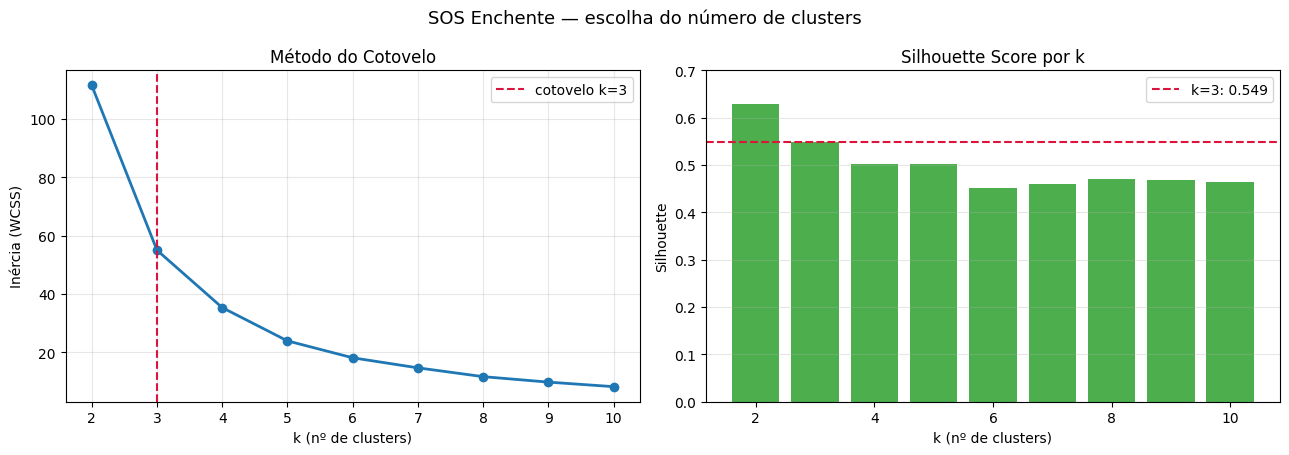

In [6]:
\
inertias, silhouettes = [], []
for k in K_RANGE:
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    modelo.fit(X)
    inertias.append(modelo.inertia_)
    silhouettes.append(silhouette_score(X, modelo.labels_))

metricas = pd.DataFrame({
    'k': list(K_RANGE),
    'Inercia': inertias,
    'Silhouette': silhouettes,
}).set_index('k')
metricas['Queda_Inercia'] = metricas['Inercia'].diff().abs()

ks = np.array(list(K_RANGE))
vetor_inercia = np.array(inertias)
k_cotovelo = int(ks[1:-1][np.argmax(np.diff(vetor_inercia, n=2))])
k_maior_silhouette = int(metricas['Silhouette'].idxmax())

print(metricas.round({'Inercia': 2, 'Silhouette': 4, 'Queda_Inercia': 2}).to_string())
print(f'\nCotovelo (maior curvatura): k = {k_cotovelo}')
print(f'Maior silhouette isolado  : k = {k_maior_silhouette} ({metricas.loc[k_maior_silhouette, "Silhouette"]:.4f})')

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6))
eixos[0].plot(metricas.index, metricas['Inercia'], marker='o', color='#1f77b4', linewidth=2)
eixos[0].axvline(k_cotovelo, color='crimson', linestyle='--', label=f'cotovelo k={k_cotovelo}')
eixos[0].set(xlabel='k (nº de clusters)', ylabel='Inércia (WCSS)', title='Método do Cotovelo')
eixos[0].legend()
eixos[0].grid(alpha=0.3)

eixos[1].bar(metricas.index, metricas['Silhouette'], color='#2ca02c', alpha=0.85)
eixos[1].axhline(
    metricas.loc[k_cotovelo, 'Silhouette'], color='crimson', linestyle='--',
    label=f'k={k_cotovelo}: {metricas.loc[k_cotovelo, "Silhouette"]:.3f}',
)
eixos[1].set(xlabel='k (nº de clusters)', ylabel='Silhouette', title='Silhouette Score por k', ylim=(0, 0.7))
eixos[1].legend()
eixos[1].grid(alpha=0.3, axis='y')

fig.suptitle('SOS Enchente — escolha do número de clusters', fontsize=13)
plt.tight_layout()
plt.show()

\
### Decisão: `k = 3`

Nos dados reais a inércia cai de **111,5 (k=2)** para **55,0 (k=3)** e depois para **35,3 (k=4)**: o ganho marginal despenca após o terceiro cluster, e a curvatura máxima ocorre em `k=3`. O Silhouette nesse ponto é **0,549**, superior ao de `k=4` (0,501), indicando boa coesão e separação.

`k=2` apresenta o maior Silhouette (0,629), mas agrupa a cidade em apenas dois níveis e **não separa** a condição de extrema pobreza da condição de alagamento extremo — informação indispensavel para decidir onde posicionar barcos antes do alerta. Por isso priorizamos o cotovelo em `k=3`, com o Silhouette como confirmação de qualidade.

In [7]:
\
K_IDEAL = k_cotovelo  # 3 nos dados reais
modelo_final = KMeans(n_clusters=K_IDEAL, random_state=RANDOM_STATE, n_init=10)
df['Cluster'] = modelo_final.fit_predict(X)

print(f'Modelo final: KMeans(k={K_IDEAL}, random_state={RANDOM_STATE}, n_init=10)')
print(f'Silhouette do modelo final: {silhouette_score(X, df["Cluster"]):.4f}')
print('\nDistritos por cluster:')
print(df.Cluster.value_counts().sort_index().to_string())
df[['Distrito_original', 'Extrema_Pobreza', 'Total_Alagamentos', 'Cluster']].head(8)

Modelo final: KMeans(k=3, random_state=42, n_init=10)
Silhouette do modelo final: 0.5487

Distritos por cluster:
Cluster
0    68
1    26
2     2


,Distrito_original,Extrema_Pobreza,Total_Alagamentos,Cluster
0,Água Rasa,1560,0,0
1,Alto de Pinheiros,99,10,0
2,Anhanguera,3755,1,0
3,Aricanduva,3069,5,0
4,Artur Alvim,4877,2,0
5,Barra Funda,310,5,0
6,Bela Vista,2145,2,0
7,Belém,3874,4,0


\
## 4. Análise das Zonas de Risco

Para cada cluster calculamos as médias das duas variáveis originais (em unidades interpretaíveis, não padronizadas). O **índice combinado de prioridade** é a soma dos z-scores dessas médias entre clusters: identifica o grupo que é simultaneamente elevado em vulnerabilidade social **e** em alagamentos, sem exigir que seja o máximo absoluto em ambas.

In [8]:
\
resumo = (
    df.groupby('Cluster')
      .agg(
          Distritos=('Distrito', 'size'),
          Media_Extrema_Pobreza=('Extrema_Pobreza', 'mean'),
          Media_Alagamentos=('Total_Alagamentos', 'mean'),
      )
      .sort_index()
)
z_medias = StandardScaler().fit_transform(resumo[['Media_Extrema_Pobreza', 'Media_Alagamentos']])
resumo['Indice_Prioridade'] = z_medias.sum(axis=1)
cluster_prioritario = int(resumo['Indice_Prioridade'].idxmax())

print(resumo.round(2).to_string())
print(f'\nCluster de Prioridade Máxima: {cluster_prioritario} '
      f'(índice combinado = {resumo.loc[cluster_prioritario, "Indice_Prioridade"]:.2f})')
print('\nDistritos do cluster prioritário:')
print(
    df.loc[df.Cluster.eq(cluster_prioritario), ['Distrito_original', 'Extrema_Pobreza', 'Total_Alagamentos']]
      .sort_values('Total_Alagamentos', ascending=False)
      .to_string(index=False)
)

         Distritos  Media_Extrema_Pobreza  Media_Alagamentos  Indice_Prioridade
Cluster                                                                        
0               68                2901.50               6.82              -2.15
1               26               10317.23              18.77               0.35
2                2                8422.00             186.50               1.80

Cluster de Prioridade Máxima: 2 (índice combinado = 1.80)

Distritos do cluster prioritário:
Distrito_original  Extrema_Pobreza  Total_Alagamentos
    Jardim Helena             8974                250
       Vila Jacuí             7870                123


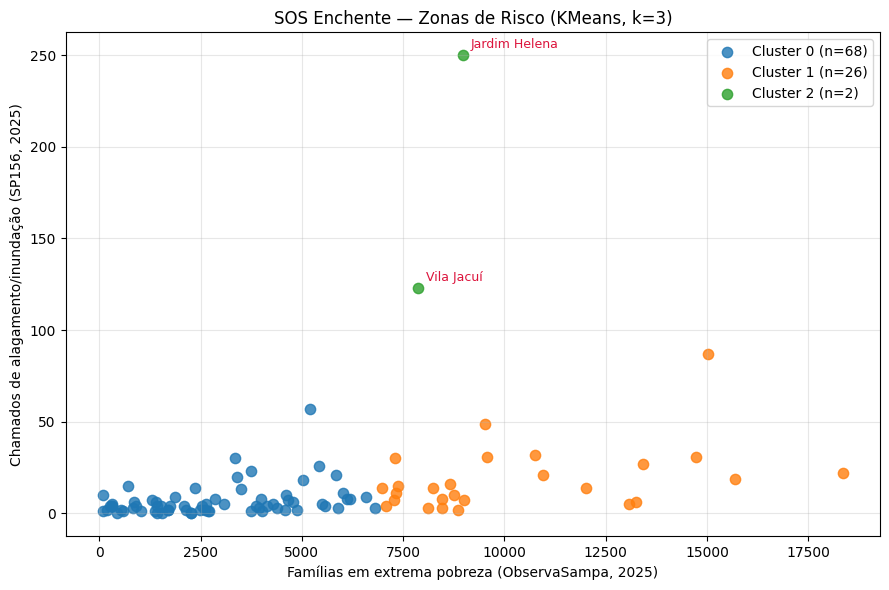

In [9]:
\
fig, ax = plt.subplots(figsize=(9, 6))
cores = plt.cm.tab10.colors
for indice, (cluster, grupo) in enumerate(df.groupby('Cluster')):
    ax.scatter(
        grupo['Extrema_Pobreza'], grupo['Total_Alagamentos'], s=55, alpha=0.8,
        color=cores[indice % len(cores)], label=f'Cluster {cluster} (n={len(grupo)})',
    )

prioritarios = df[df.Cluster.eq(cluster_prioritario)]
for _, linha in prioritarios.iterrows():
    ax.annotate(
        linha['Distrito_original'],
        (linha['Extrema_Pobreza'], linha['Total_Alagamentos']),
        xytext=(6, 5), textcoords='offset points', fontsize=9, color='crimson',
    )

ax.set(
    xlabel='Famílias em extrema pobreza (ObservaSampa, 2025)',
    ylabel='Chamados de alagamento/inundação (SP156, 2025)',
    title=f'SOS Enchente — Zonas de Risco (KMeans, k={K_IDEAL})',
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

\
## 5. Conclusão — Cluster de Prioridade Máxima

O **Cluster 2** é a Zona de Prioridade Máxima. Ele reúne **Jardim Helena** (8.974 famílias em extrema pobreza; **250** chamados de alagamento/inundação) e **Vila Jacuí** (7.870 famílias; **123** chamados). As médias do cluster são **8.422 famílias** e **186,5 alagamentos** por distrito: a segunda maior média de vulnerabilidade e, com folga, a maior exposição hídrica da cidade.

**Interpretação para a Defesa Civil:** ao receber um alerta meteorológico severo, barcos, ambulâncias e equipes do SUS devem ser posicionados preventivamente nesses dois distritos antes que as vias cortem o acesso. O Cluster 1 (26 distritos, 10.317 famílias e 18,8 chamados em média) merece o segundo escalão — vigilância e abrigos —, enquanto o Cluster 0 (68 distritos, 2.902 famílias e 6,8 chamados) permanece em monitoramento padrão.